# 4. Finite Metallic Back-Reflector & Lossless Substrate Invariant

## Physical Motivation & Learning Objectives
In scattering-matrix formalisms, **semi-infinite substrates and superstrates must be lossless** ($\operatorname{Im}(n) = 0$). This invariant ensures that propagating diffraction orders satisfy energy conservation and can be cleanly separated from evanescent decay.

In this tutorial:
1. We explain why metallic substrates cannot be semi-infinite in EMUstack.
2. We demonstrate how to correctly model an optically thick metallic mirror ($100$ nm Ag) backed by a lossless glass substrate.



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



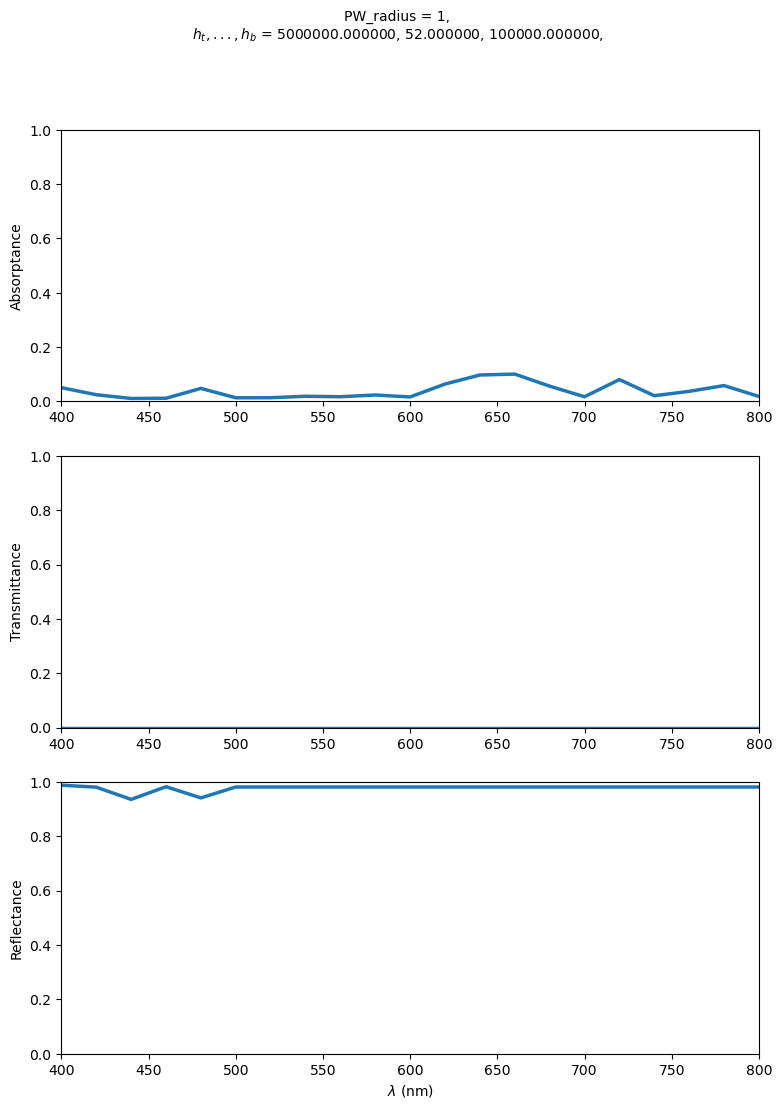

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

wl_1 = 400.0
wl_2 = 800.0
no_wl_1 = 21
wavelengths = np.linspace(wl_1, wl_2, no_wl_1)
light_list = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]

period = 300.0
superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air)
TF_2 = objects.ThinFilm(period, height_nm=5e6, material=materials.InP, loss=False)
TF_3 = objects.ThinFilm(period, height_nm=52.0, material=materials.Si_a)
mirror = objects.ThinFilm(period, height_nm=1e5, material=materials.Ag)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_mir = mirror.calc_modes(light)
    sim_2   = TF_2.calc_modes(light)
    sim_3   = TF_3.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    stk = Stack((sim_sub, sim_mir, sim_3, sim_2, sim_sup))
    stk.calc_scat(pol='TM')
    return stk

stacks_list = [simulate_stack(l) for l in light_list]

figs_tra = plotting.t_r_a_plots(stacks_list)
plt.show()


## Structure Definition: Air / Absorber / Ag Mirror / Glass Substrate


## Spectra Evaluation


## Physical Interpretation
- The $100$ nm silver layer acts as an opaque back-reflector with transmission $T \to 0$.
- Placing the metallic mirror above a lossless substrate satisfies the boundary condition invariant while capturing the optical physics of a mirrored substrate.
